# Tarea guiada: ¿quién va a abandonar la universidad?

## Tres modelos, un problema, una decisión

**Contexto.** Una universidad privada de El Salvador pierde cada año cerca de 1 de cada 5 estudiantes antes de terminar su carrera. La Dirección de Bienestar Estudiantil puede ofrecer **tutorías, apoyo financiero y seguimiento** a los estudiantes en riesgo, pero no a todos: necesita saber **a quién llamar primero**.

**Tu trabajo:** construir y comparar **tres modelos de clasificación** (regresión logística, Random Forest y Gradient Boosting), elegir el mejor con argumentos y entregar una lista de estudiantes en riesgo.

### Archivos

| Archivo | Qué contiene |
|---|---|
| `estudiantes_historico.csv` | 6,040 registros históricos con la columna `abandono` (1 = abandonó, 0 = siguió) |
| `estudiantes_nuevos.csv` | 300 estudiantes actuales **sin** la columna `abandono`: a ellos les vas a predecir |

### Qué entregas en Moodle

1. Este notebook **ejecutado**, con el nombre `Apellido_Nombre_Tarea_Tres_Modelos.ipynb`.
2. `modelo_desercion.joblib`: tu modelo final guardado.
3. `predicciones_nuevos.csv`: la lista de riesgo de los 300 estudiantes nuevos.

### Reglas

- **Usa exactamente los nombres de variables que pide cada tarea.** Las celdas de verificación los necesitan.
- **No modifiques las celdas marcadas como VERIFICACIÓN.** Si una verificación falla, corrige tu código antes de seguir.
- Usa siempre `random_state=42` (ya viene en `RANDOM_STATE`).
- Antes de entregar: **Entorno de ejecución → Reiniciar y ejecutar todo**. Si el notebook no corre de principio a fin sin errores, se descuentan **10 puntos**.
- Las respuestas escritas van en las celdas de texto marcadas con ✍️. Deben apoyarse en números que tu notebook muestre.

### Rúbrica (100 puntos)

| Parte | Qué se evalúa | Puntos |
|---|---|---|
| 1. Exploración | Duplicados, limpieza de `trabaja`, tasa de abandono, 2 gráficas y 3 hallazgos | 10 |
| 2. Preparación | División estratificada y los dos preprocesadores | 10 |
| 3. Baseline | `DummyClassifier` y su interpretación | 5 |
| 4. Regresión logística | Pipeline, búsqueda de hiperparámetros, métricas e interpretación de coeficientes | 15 |
| 5. Random Forest | Pipeline, búsqueda de hiperparámetros, métricas e importancias | 15 |
| 6. Gradient Boosting | Pipeline con early stopping, búsqueda, métricas | 15 |
| 7. Comparación | Tabla comparativa, curvas ROC, matrices de confusión y elección justificada | 15 |
| 8. Decisión de negocio | Umbral por costo e importancia por permutación | 5 |
| 9. Entregables | Modelo guardado y archivo de predicciones correcto | 5 |
| 10. Conclusiones | Respuestas escritas, apoyadas en evidencia | 5 |
| | **Total** | **100** |

## Parte 0 · Preparación del entorno (dada)

Sube `estudiantes_historico.csv` y `estudiantes_nuevos.csv` al panel **Archivos** de Colab y ejecuta estas celdas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("estudiantes_historico.csv")
print(df.shape)
df.head()

(6040, 17)


,estudiante_id,carrera,edad,ciclo_actual,tipo_colegio,nota_admision,promedio_acumulado,materias_reprobadas,materias_inscritas,asistencia_pct,trabaja,horas_trabajo_semana,tipo_beca,pagos_atrasados,distancia_campus_km,horas_plataforma_semana,abandono
0,EST-03355,Ingenieria Industrial,25,2,Publico,6.5,7.76,0,3,86.7,Si,29,Ninguna,4,5.2,5.8,0
1,EST-02879,Ingenieria en Sistemas,17,7,Publico,7.2,8.63,0,5,81.8,No,0,Ninguna,0,5.0,4.7,0
2,EST-00164,Ingenieria Industrial,20,2,Privado,6.3,5.87,2,4,85.2,No,0,Ninguna,3,4.3,6.8,1
3,EST-02602,Derecho,21,6,Publico,6.1,6.79,0,6,88.4,No,0,Parcial,1,5.6,8.4,0
4,EST-05849,Ingenieria Industrial,29,1,Publico,8.4,6.94,1,5,78.0,No,0,Ninguna,1,5.9,3.6,0


## Parte 1 · Exploración y limpieza (10 puntos)

### Tarea 1.1 — Duplicados (2 pts)
Cuenta las filas duplicadas exactas y elimínalas. El resultado debe quedar en la misma variable `df`.

In [3]:
# Tarea 1.1 - Duplicados exactos
print("Filas duplicadas exactas:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Filas que quedan:", df.shape[0])


Filas duplicadas exactas: 40
Filas que quedan: 6000


> **Punto de control:** 40 duplicados; quedan **6,000** filas.

### Tarea 1.2 — Limpiar la columna `trabaja` (2 pts)
Revisa sus valores con `value_counts()`. Verás variantes como `"SI "` o `"NO "`. Déjala solo con los valores `"Si"` y `"No"` (pista: `.str.strip()` y `.str.capitalize()`).

In [4]:
# Tarea 1.2 - Limpiar la columna trabaja
print("Antes:")
print(df["trabaja"].value_counts(dropna=False))

df["trabaja"] = df["trabaja"].str.strip().str.capitalize()

print("\nDespues:")
print(df["trabaja"].value_counts(dropna=False))


Antes:
trabaja
No     3180
Si     2658
NO       89
SI       73
Name: count, dtype: int64

Despues:
trabaja
No    3269
Si    2731
Name: count, dtype: int64


In [5]:
# VERIFICACIÓN — no modificar
problemas = []
if df.duplicated().sum() != 0:
    problemas.append("Todavía hay filas duplicadas en df.")
if set(df["trabaja"].dropna().unique()) != {"Si", "No"}:
    problemas.append("La columna trabaja debe tener solo los valores 'Si' y 'No'.")
print("Todo bien, continúa." if not problemas else "\n".join(problemas))

Todo bien, continúa.


### Tarea 1.3 — Tasa de abandono (2 pts)
Calcula qué proporción de estudiantes abandonó. ¿Las clases están balanceadas?

In [6]:
# Tarea 1.3 - Tasa de abandono
tasa_abandono = df["abandono"].value_counts(normalize=True).sort_index()
print(tasa_abandono.round(4))
print("\nTasa de abandono:", round(df["abandono"].mean(), 4))


abandono
0    0.8083
1    0.1917
Name: proportion, dtype: float64

Tasa de abandono: 0.1917


> **Punto de control:** alrededor del **19%** abandonó.

### Tarea 1.4 — Dos gráficas (2 pts)
Haz **dos** gráficas que muestren cómo se relaciona el abandono con otras variables. Sugerencias: tasa de abandono por `tipo_beca`, por `pagos_atrasados` o por `ciclo_actual`; o un boxplot de `promedio_acumulado` o `asistencia_pct` separado por `abandono`.

tipo_beca
Ninguna     0.210
Parcial     0.171
Completa    0.091
Name: abandono, dtype: float64


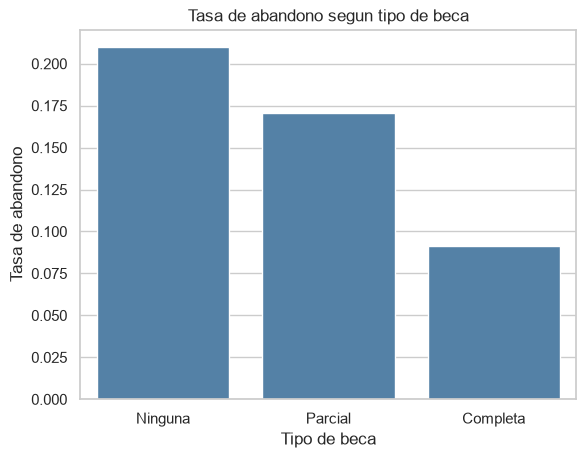

In [7]:
# Grafica 1: tasa de abandono por tipo de beca
orden_beca = ["Ninguna", "Parcial", "Completa"]
tasa_por_beca = df.groupby("tipo_beca")["abandono"].mean().reindex(orden_beca)
print(tasa_por_beca.round(3))

sns.barplot(data=df, x="tipo_beca", y="abandono", order=orden_beca, errorbar=None, color="steelblue")
plt.title("Tasa de abandono segun tipo de beca")
plt.ylabel("Tasa de abandono")
plt.xlabel("Tipo de beca")
plt.show()


           count  mean   std   min   25%   50%   75%   max
abandono                                                  
0         4850.0  7.01  1.10  2.57  6.30  7.03  7.73  10.0
1         1150.0  6.08  1.18  2.42  5.34  5.89  6.82  10.0


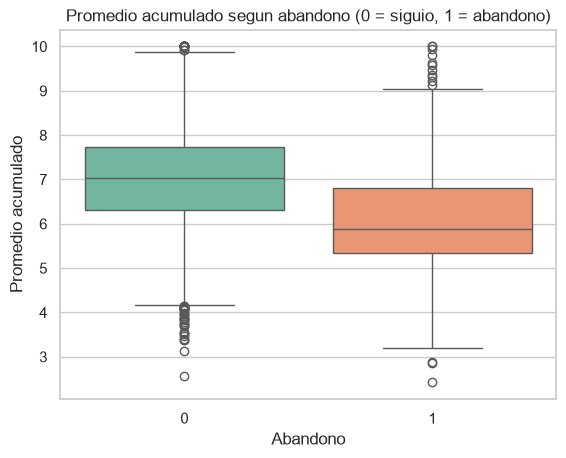

In [8]:
# Grafica 2: promedio acumulado segun abandono
print(df.groupby("abandono")["promedio_acumulado"].describe().round(2))

sns.boxplot(data=df, x="abandono", y="promedio_acumulado", hue="abandono", palette="Set2", legend=False)
plt.title("Promedio acumulado segun abandono (0 = siguio, 1 = abandono)")
plt.xlabel("Abandono")
plt.ylabel("Promedio acumulado")
plt.show()


### ✍️ Tarea 1.5 — Tres hallazgos (2 pts)
Escribe tres observaciones concretas sobre los datos, cada una con un número que la respalde.

1. De los 6,040 registros originales, 40 eran duplicados exactos, quedan 6000. En `trabaja` había 162 valores mal escritos que se normalizaron a 3,269 "No" y 2,731 "Si".

2. Las clases están desbalanceadas: 19.17% abandonó (1,150) y 80.83% siguió. Por eso la exactitud es engañosa.

3. A mejor beca hay menos abandono: 21.0% en "Ninguna", 17.1% en "Parcial" y 9.1% en "Completa". Quien abandona tiene menor promedio acumulado: mediana 5.89 frente a 7.03 de quien sigue.

## Parte 2 · Preparación (10 puntos)

### Tarea 2.1 — División de los datos (4 pts)
- `X`: todas las columnas **excepto** `estudiante_id` y `abandono`.
- `y`: la columna `abandono`.
- Divide en `X_train`, `X_test`, `y_train`, `y_test` con `test_size=0.2`, `random_state=RANDOM_STATE` y **`stratify=y`**.

In [9]:
# Tarea 2.1 - Division de los datos
X = df.drop(columns=["estudiante_id", "abandono"])
y = df["abandono"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Abandono en train:", round(y_train.mean(), 4))
print("Abandono en test:", round(y_test.mean(), 4))


X_train: (4800, 15) | X_test: (1200, 15)
Abandono en train: 0.1917
Abandono en test: 0.1917


> **Punto de control:** 4,800 filas de entrenamiento y 1,200 de prueba, con la misma proporción de abandono en las dos.

### Tarea 2.2 — Dos preprocesadores (6 pts)

Las listas de columnas ya vienen dadas. `tipo_beca` tiene un orden real: **Ninguna < Parcial < Completa**.

Construye **dos** `ColumnTransformer`:

- **`preprocessor_escalado`** (para la regresión logística): numéricas con `SimpleImputer(strategy="median")` + `StandardScaler()`; `tipo_beca` con `SimpleImputer(strategy="most_frequent")` + `OrdinalEncoder` con el orden correcto; nominales con `OneHotEncoder(handle_unknown="ignore", drop="if_binary")`.
- **`preprocessor_arboles`** (para Random Forest y boosting): igual, pero **sin** `StandardScaler`.

In [10]:
numeric_features = ["edad", "ciclo_actual", "nota_admision", "promedio_acumulado", "materias_reprobadas",
                    "materias_inscritas", "asistencia_pct", "horas_trabajo_semana", "pagos_atrasados",
                    "distancia_campus_km", "horas_plataforma_semana"]
ordinal_features = ["tipo_beca"]
nominal_features = ["carrera", "tipo_colegio", "trabaja"]

In [11]:
# Tarea 2.2 - Los dos preprocesadores
orden_beca = [["Ninguna", "Parcial", "Completa"]]

# Regresion logistica: imputacion + escalado para numericas, ordinal para tipo_beca, one-hot para nominales
preprocessor_escalado = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=orden_beca)),
    ]), ordinal_features),
    ("nom", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), nominal_features),
])

# Arboles: igual, pero sin StandardScaler (no lo necesitan)
preprocessor_arboles = ColumnTransformer(transformers=[
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=orden_beca)),
    ]), ordinal_features),
    ("nom", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), nominal_features),
])

print("Preprocesadores listos.")


Preprocesadores listos.


In [12]:
# VERIFICACIÓN — no modificar
problemas = []
if "y_train" not in globals() or "y_test" not in globals():
    problemas.append("Faltan X_train, X_test, y_train o y_test: completa la Tarea 2.1.")
elif round(y_train.mean(), 2) != round(y_test.mean(), 2):
    problemas.append("La proporción de abandono no coincide entre train y test: ¿usaste stratify=y?")
for nombre in ["preprocessor_escalado", "preprocessor_arboles"]:
    if nombre not in globals():
        problemas.append(f"No existe la variable {nombre}.")
    elif "X_train" in globals():
        salida = globals()[nombre].fit_transform(X_train)
        if np.isnan(np.asarray(salida, dtype=float)).any():
            problemas.append(f"{nombre} deja valores faltantes: revisa los imputadores.")
print("Todo bien, continúa." if not problemas else "\n".join(problemas))

Todo bien, continúa.


## Parte 3 · Modelo de referencia (5 puntos)

### Tarea 3.1 — Baseline (3 pts)
Entrena un `DummyClassifier(strategy="most_frequent")` llamado `baseline` e imprime su exactitud, su recall y su AUC en prueba.

In [13]:
# Tarea 3.1 - Baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)
proba_baseline = baseline.predict_proba(X_test)[:, 1]

print("Exactitud:", round(accuracy_score(y_test, pred_baseline), 4))
print("Recall:", round(recall_score(y_test, pred_baseline), 4))
print("AUC:", round(roc_auc_score(y_test, proba_baseline), 4))


Exactitud: 0.8083
Recall: 0.0
AUC: 0.5


> **Punto de control:** exactitud ≈ **0.81**, recall **0**, AUC **0.5**.

### ✍️ Tarea 3.2 — Interpretación (2 pts)
¿Por qué este modelo tiene una exactitud alta y aun así no le sirve a la universidad? ¿Qué métrica usarás para comparar los modelos y por qué?

*Tu respuesta:*

El baseline siempre predice la clase mayoritaria ("no abandona"): acierta el 80.83% (exactitud 0.8083) sin haber aprendido nada, con recall 0.0 y AUC 0.5. Por ende no distingue a un estudiante en riesgo de uno que no lo está, así que no sirve para decidir a quién llamar. Para comparar los modelos conviene el AUC

## Parte 4 · Modelo 1: regresión logística (15 puntos)

### Tarea 4.1 — Búsqueda de hiperparámetros (7 pts)
1. Crea `pipe_logistica`: `Pipeline` con `("preprocessor", preprocessor_escalado)` y `("model", LogisticRegression(max_iter=2000))`.
2. Crea `grid_logistica`: `GridSearchCV` que pruebe `model__C` en `[0.01, 0.1, 1, 10]` y `model__class_weight` en `[None, "balanced"]`, con `cv=5`, `scoring="roc_auc"` y `n_jobs=-1`.
3. Entrénalo e imprime `best_params_` y `best_score_`.

In [14]:
# Tarea 4.1 - Busqueda de hiperparametros
pipe_logistica = Pipeline([
    ("preprocessor", preprocessor_escalado),
    ("model", LogisticRegression(max_iter=2000)),
])

grid_logistica = GridSearchCV(
    pipe_logistica,
    {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    cv=5, scoring="roc_auc", n_jobs=-1,
)

grid_logistica.fit(X_train, y_train)

print("Mejores parametros:", grid_logistica.best_params_)
print("AUC en validacion cruzada:", round(grid_logistica.best_score_, 4))


Mejores parametros: {'model__C': 1, 'model__class_weight': None}
AUC en validacion cruzada: 0.7964


> **Punto de control:** AUC CV alrededor de **0.80**.

### Tarea 4.2 — Métricas en prueba (4 pts)
Guarda el mejor modelo en `modelo_logistica` (`grid_logistica.best_estimator_`). Imprime su `classification_report` y su AUC en prueba.

In [15]:
# Tarea 4.2 - Metricas en prueba
modelo_logistica = grid_logistica.best_estimator_

print(classification_report(y_test, modelo_logistica.predict(X_test), digits=3))
print("AUC en prueba:", round(roc_auc_score(y_test, modelo_logistica.predict_proba(X_test)[:, 1]), 4))


              precision    recall  f1-score   support

           0      0.857     0.967     0.908       970
           1      0.695     0.317     0.436       230

    accuracy                          0.843      1200
   macro avg      0.776     0.642     0.672      1200
weighted avg      0.826     0.843     0.818      1200

AUC en prueba: 0.8226


### Tarea 4.3 — Coeficientes (4 pts)
Muestra los coeficientes del modelo con el nombre de cada columna, ordenados. Luego responde: ¿qué **tres** variables aumentan más el riesgo de abandono y cuáles lo reducen?

In [16]:
# Tarea 4.3 - Coeficientes
nombres_logistica = modelo_logistica.named_steps["preprocessor"].get_feature_names_out()
coeficientes = pd.Series(
    modelo_logistica.named_steps["model"].coef_[0], index=nombres_logistica
).sort_values()

print("Variables que mas REDUCEN el riesgo:")
print(coeficientes.head(8).round(3).to_string())
print("\nVariables que mas AUMENTAN el riesgo:")
print(coeficientes.tail(8).round(3).to_string())


Variables que mas REDUCEN el riesgo:
nom__trabaja_Si                           -1.038
num__promedio_acumulado                   -0.662
num__asistencia_pct                       -0.414
nom__carrera_Derecho                      -0.406
ord__tipo_beca                            -0.388
num__ciclo_actual                         -0.328
nom__carrera_Administracion de Empresas   -0.277
nom__carrera_Contaduria                   -0.215

Variables que mas AUMENTAN el riesgo:
num__materias_inscritas                0.055
nom__tipo_colegio_Publico              0.093
num__edad                              0.097
num__distancia_campus_km               0.099
nom__carrera_Ingenieria en Sistemas    0.148
num__pagos_atrasados                   0.324
num__materias_reprobadas               0.362
num__horas_trabajo_semana              0.857


✍️ *Tu respuesta:*

Aumentan el riesgo: `horas_trabajo_semana` (+0.857), `materias_reprobadas` (+0.362) y `pagos_atrasados` (+0.324). Lo reducen: `trabaja_Si` (-1.038), `promedio_acumulado` (-0.662) y `asistencia_pct` (-0.414); más abajo quedan `tipo_beca` (-0.388, a mejor beca menos riesgo) y `ciclo_actual` (-0.328).

## Parte 5 · Modelo 2: Random Forest (15 puntos)

### Tarea 5.1 — Búsqueda de hiperparámetros (7 pts)
1. Crea `pipe_bosque`: `Pipeline` con `("preprocessor", preprocessor_arboles)` y `("model", RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))`.
2. Crea `grid_bosque` probando `model__max_depth` en `[6, 10, None]` y `model__min_samples_leaf` en `[1, 5, 20]`, con `cv=5`, `scoring="roc_auc"` y `n_jobs=-1`.
3. Entrénalo e imprime `best_params_` y `best_score_`. *(Puede tardar uno o dos minutos.)*

In [17]:
# Tarea 5.1 - Busqueda de hiperparametros del bosque
pipe_bosque = Pipeline([
    ("preprocessor", preprocessor_arboles),
    ("model", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
])

grid_bosque = GridSearchCV(
    pipe_bosque,
    {"model__max_depth": [6, 10, None], "model__min_samples_leaf": [1, 5, 20]},
    cv=5, scoring="roc_auc", n_jobs=-1,
)

grid_bosque.fit(X_train, y_train)

print("Mejores parametros:", grid_bosque.best_params_)
print("AUC en validacion cruzada:", round(grid_bosque.best_score_, 4))


Mejores parametros: {'model__max_depth': 10, 'model__min_samples_leaf': 20}
AUC en validacion cruzada: 0.8237


> **Punto de control:** AUC CV alrededor de **0.82**.

### Tarea 5.2 — Métricas en prueba (4 pts)
Guarda el mejor modelo en `modelo_bosque`. Imprime su `classification_report` y su AUC en prueba.

In [18]:
# Tarea 5.2 - Metricas en prueba
modelo_bosque = grid_bosque.best_estimator_

print(classification_report(y_test, modelo_bosque.predict(X_test), digits=3))
print("AUC en prueba:", round(roc_auc_score(y_test, modelo_bosque.predict_proba(X_test)[:, 1]), 4))


              precision    recall  f1-score   support

           0      0.928     0.761     0.836       970
           1      0.427     0.752     0.545       230

    accuracy                          0.759      1200
   macro avg      0.678     0.756     0.691      1200
weighted avg      0.832     0.759     0.780      1200

AUC en prueba: 0.844


### Tarea 5.3 — Importancia de variables (4 pts)
Muestra las **10** variables con mayor `feature_importances_`. ¿Coinciden con las que destacó la regresión logística? ¿Qué te dice la importancia que **no** te dice un coeficiente?

In [19]:
# Tarea 5.3 - Importancia de variables
nombres_bosque = modelo_bosque.named_steps["preprocessor"].get_feature_names_out()
importancias_bosque = pd.Series(
    modelo_bosque.named_steps["model"].feature_importances_, index=nombres_bosque
).sort_values(ascending=False)

print(importancias_bosque.head(10).round(4).to_string())


num__promedio_acumulado         0.3215
num__materias_reprobadas        0.1674
num__asistencia_pct             0.1333
num__horas_trabajo_semana       0.0950
num__pagos_atrasados            0.0507
num__nota_admision              0.0436
num__ciclo_actual               0.0413
num__horas_plataforma_semana    0.0377
num__distancia_campus_km        0.0358
num__edad                       0.0200


✍️ *Tu respuesta:*

Las 10 variables más importantes: `promedio_acumulado` (0.3215), `materias_reprobadas` (0.1674), `asistencia_pct` (0.1333), `horas_trabajo_semana` (0.0950), `pagos_atrasados` (0.0507), `nota_admision` (0.0436), `ciclo_actual` (0.0413), `horas_plataforma_semana` (0.0377), `distancia_campus_km` (0.0358) y `edad` (0.0200).

Coinciden en buena parte con la regresión: promedio_acumulado, materias_reprobadas, asistencia_pct, horas_trabajo_semana y pagos_atrasados están arriba en los dos. Lo que aporta la importancia es cuánto usa el modelo cada variable, pero no la dirección del efecto; tampoco es un tamaño de efecto comparable entre variables, porque las continuas suelen verse más importantes que las binarias.

## Parte 6 · Modelo 3: Gradient Boosting (15 puntos)

### Tarea 6.1 — Búsqueda de hiperparámetros (8 pts)
1. Crea `pipe_boosting`: `Pipeline` con `("preprocessor", preprocessor_arboles)` y `("model", HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, scoring="roc_auc", class_weight="balanced", random_state=RANDOM_STATE))`.
2. Crea `grid_boosting` probando `model__learning_rate` en `[0.05, 0.1, 0.3]` y `model__max_depth` en `[2, 3, None]`, con `cv=5`, `scoring="roc_auc"` y `n_jobs=-1`.
3. Entrénalo e imprime `best_params_` y `best_score_`.

In [20]:
# Tarea 6.1 - Busqueda de hiperparametros del boosting
# Nota: HistGradientBoostingClassifier no acepta el argumento "scoring"; el scoring se define en GridSearchCV.
pipe_boosting = Pipeline([
    ("preprocessor", preprocessor_arboles),
    ("model", HistGradientBoostingClassifier(
        max_iter=1000, early_stopping=True, class_weight="balanced", random_state=RANDOM_STATE)),
])

grid_boosting = GridSearchCV(
    pipe_boosting,
    {"model__learning_rate": [0.05, 0.1, 0.3], "model__max_depth": [2, 3, None]},
    cv=5, scoring="roc_auc", n_jobs=-1,
)

grid_boosting.fit(X_train, y_train)

print("Mejores parametros:", grid_boosting.best_params_)
print("AUC en validacion cruzada:", round(grid_boosting.best_score_, 4))


Mejores parametros: {'model__learning_rate': 0.1, 'model__max_depth': 2}
AUC en validacion cruzada: 0.8286


> **Punto de control:** AUC CV alrededor de **0.83**.

### Tarea 6.2 — Métricas en prueba y árboles usados (7 pts)
Guarda el mejor modelo en `modelo_boosting`. Imprime su `classification_report`, su AUC en prueba y cuántos árboles usó (`n_iter_` del paso `"model"`). ¿Por qué no usó los 1,000 árboles permitidos?

In [21]:
# Tarea 6.2 - Metricas en prueba y arboles usados
modelo_boosting = grid_boosting.best_estimator_

print(classification_report(y_test, modelo_boosting.predict(X_test), digits=3))
print("AUC en prueba:", round(roc_auc_score(y_test, modelo_boosting.predict_proba(X_test)[:, 1]), 4))
print("Arboles usados (n_iter_):", modelo_boosting.named_steps["model"].n_iter_)


              precision    recall  f1-score   support

           0      0.929     0.782     0.849       970
           1      0.449     0.748     0.561       230

    accuracy                          0.776      1200
   macro avg      0.689     0.765     0.705      1200
weighted avg      0.837     0.776     0.794      1200

AUC en prueba: 0.8492
Arboles usados (n_iter_): 113


✍️ *Tu respuesta:*

AUC 0.8492 en prueba, con precisión 0.449, recall 0.748 y F1 0.561 en la clase 1, y exactitud 0.776.

Usó solo 113 de los 1,000 árboles permitidos. Con `early_stopping=True` el modelo reserva datos para validación interna y se detiene cuando la pérdida de validación deja de mejorar (`n_iter_no_change=10`). Los árboles siguientes no aportaban y habrían empezado a sobreajustar: los 1,000 eran un tope, no un objetivo.

## Parte 7 · Comparación de los tres modelos (15 puntos)

### Tarea 7.1 — Tabla comparativa (5 pts)
Construye un `DataFrame` llamado `comparacion`, con una fila por modelo (**Logística**, **Random Forest**, **Boosting**) y estas columnas:

- `AUC_CV`: el `best_score_` de su búsqueda.
- `AUC_test`, `Precision`, `Recall`, `F1`: calculadas en prueba (las tres últimas con `predict`, es decir, umbral 0.5).

Pista: arma un diccionario por modelo y pásale la lista a `pd.DataFrame(...)`, o completa la tabla fila por fila.

In [22]:
# Tarea 7.1 - Tabla comparativa
def fila_comparacion(nombre, modelo, auc_cv):
    proba = modelo.predict_proba(X_test)[:, 1]
    pred = modelo.predict(X_test)
    return {
        "Modelo": nombre,
        "AUC_CV": round(auc_cv, 4),
        "AUC_test": round(roc_auc_score(y_test, proba), 4),
        "Precision": round(precision_score(y_test, pred), 4),
        "Recall": round(recall_score(y_test, pred), 4),
        "F1": round(f1_score(y_test, pred), 4),
    }

comparacion = pd.DataFrame([
    fila_comparacion("Logistica", modelo_logistica, grid_logistica.best_score_),
    fila_comparacion("Random Forest", modelo_bosque, grid_bosque.best_score_),
    fila_comparacion("Boosting", modelo_boosting, grid_boosting.best_score_),
]).set_index("Modelo")

comparacion


,AUC_CV,AUC_test,Precision,Recall,F1
Modelo,,,,,
Logistica,0.7964,0.8226,0.6952,0.3174,0.4358
Random Forest,0.8237,0.8440,0.4272,0.7522,0.5449
Boosting,0.8286,0.8492,0.4491,0.7478,0.5612


In [23]:
# VERIFICACIÓN — no modificar
problemas = []
if "comparacion" not in globals():
    problemas.append("No existe la variable comparacion.")
else:
    faltan = {"AUC_CV", "AUC_test", "Precision", "Recall", "F1"} - set(comparacion.columns)
    if faltan:
        problemas.append(f"Faltan columnas en comparacion: {faltan}")
    if len(comparacion) != 3:
        problemas.append("comparacion debe tener exactamente 3 filas, una por modelo.")
print("Todo bien, continúa." if not problemas else "\n".join(problemas))

Todo bien, continúa.


### Tarea 7.2 — Curvas ROC juntas (4 pts)
Dibuja las curvas ROC de los tres modelos **en una misma gráfica** (pista: `RocCurveDisplay.from_estimator(modelo, X_test, y_test, name=..., ax=ax)` con el mismo `ax` para los tres).

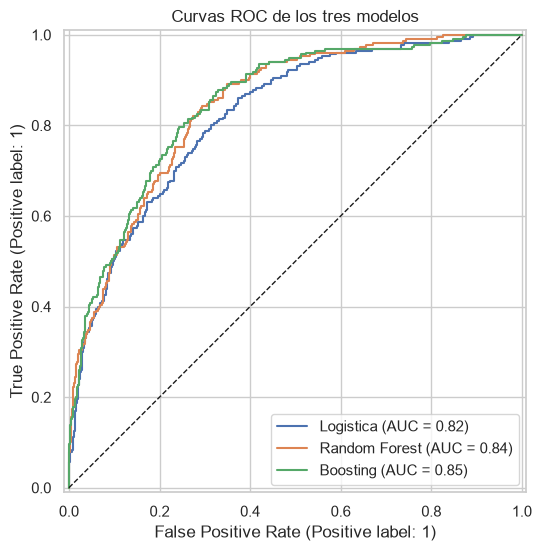

In [24]:
# Tarea 7.2 - Curvas ROC juntas
modelos = [("Logistica", modelo_logistica), ("Random Forest", modelo_bosque), ("Boosting", modelo_boosting)]

fig, ax = plt.subplots(figsize=(7, 6))
for nombre, modelo in modelos:
    RocCurveDisplay.from_estimator(modelo, X_test, y_test, name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_title("Curvas ROC de los tres modelos")
plt.show()


### Tarea 7.3 — Matrices de confusión (3 pts)
Dibuja las tres matrices de confusión lado a lado (pista: `fig, axes = plt.subplots(1, 3, figsize=(15, 4))` y `ConfusionMatrixDisplay.from_estimator(..., ax=axes[i])`).

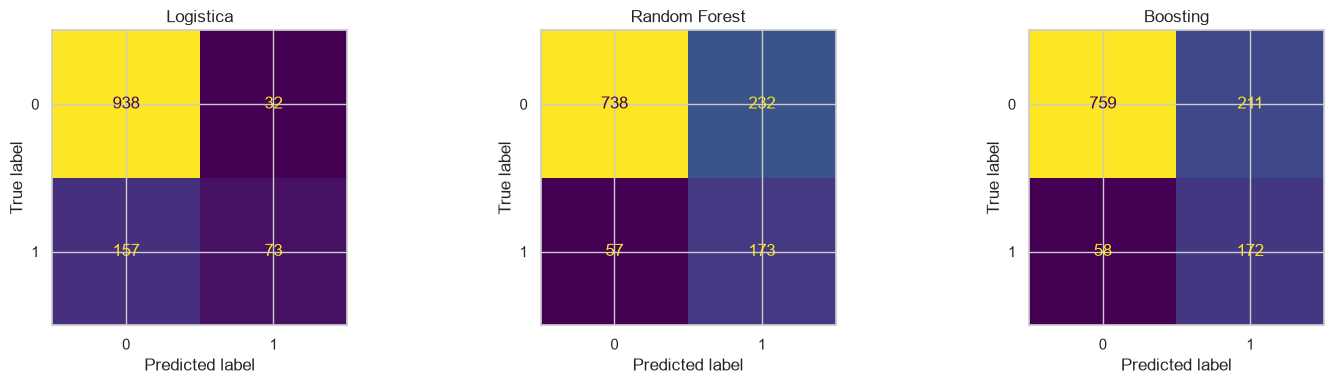

In [25]:
# Tarea 7.3 - Matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, modelo) in zip(axes, modelos):
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()


### ✍️ Tarea 7.4 — ¿Cuál elegirías? (3 pts)
Elige **un** modelo final y justifícalo con números de tu tabla: desempeño (AUC en validación cruzada y en prueba), qué tan grande es la diferencia con los otros, y qué tan fácil es de explicar a la Dirección.

**Cuidado:** Precision, Recall y F1 dependen del umbral 0.5 y de si el modelo usó `class_weight="balanced"`; el AUC no depende del umbral. Compara primero con el AUC, y usa las otras métricas para entender los errores.

*Tu respuesta:*

Se elige el Boosting: es el mejor en las dos medidas, con AUC 0.8286 en validación cruzada y 0.8492 en prueba, contra 0.8237 y 0.8440 del Random Forest y 0.7964 y 0.8226 de la logística. La ventaja sobre el bosque es mínima  de 0.005.

Al umbral 0.5, el Boosting y el bosque tienen precisión baja (0.449 y 0.427), mientras que la logística es más conservadora (precisión 0.695, recall 0.317). Para Bienestar Estudiantil, dejar escapar desertores cuesta más que hacer llamadas de más, así que ese intercambio conviene.

La logística sería más fácil de explicar, pero el Boosting también se justifica con la importancia por permutación de la Tarea 8.2 y no requiere escalado.

Guarda tu modelo elegido en la variable **`modelo_final`** (por ejemplo, `modelo_final = modelo_boosting`).

In [26]:
# modelo_final = el modelo que elegiste
modelo_final = modelo_boosting


## Parte 8 · Decisión de negocio (5 puntos)

### Tarea 8.1 — Umbral según el costo (3 pts)
La universidad estima que:

- **Perder** a un estudiante que abandona cuesta **$1,200** (colegiaturas que ya no pagará).
- **Intervenir** (tutoría y seguimiento) a un estudiante cuesta **$60**, abandone o no.

Para cada umbral en `[0.1, 0.2, 0.3, 0.4, 0.5, 0.6]` calcula con tu `modelo_final` en prueba:

- `perdidos`: estudiantes que abandonaron y **no** fueron marcados.
- `intervenidos`: todos los estudiantes marcados (probabilidad ≥ umbral).
- `costo = perdidos × 1200 + intervenidos × 60`

Imprime los resultados y guarda en **`umbral_elegido`** el de menor costo.

In [27]:
# Tarea 8.1 - Umbral segun el costo
proba_final = modelo_final.predict_proba(X_test)[:, 1]

filas_umbral = []
for umbral in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    marcados = proba_final >= umbral
    perdidos = int(((y_test == 1) & (~marcados)).sum())
    intervenidos = int(marcados.sum())
    filas_umbral.append({
        "umbral": umbral,
        "perdidos": perdidos,
        "intervenidos": intervenidos,
        "costo": perdidos * 1200 + intervenidos * 60,
    })

tabla_umbrales = pd.DataFrame(filas_umbral)
print(tabla_umbrales.to_string(index=False))

umbral_elegido = float(tabla_umbrales.loc[tabla_umbrales["costo"].idxmin(), "umbral"])
print("\nUmbral elegido:", umbral_elegido)


 umbral  perdidos  intervenidos  costo
    0.1         0          1180  70800
    0.2         7           832  58320
    0.3        21           588  60480
    0.4        40           469  76140
    0.5        58           383  92580
    0.6        85           291 119460

Umbral elegido: 0.2


### Tarea 8.2 — ¿Qué variables importan? (2 pts)
Calcula `permutation_importance` de tu `modelo_final` sobre `X_test`, `y_test` con `scoring="roc_auc"`, `n_repeats=5`, `random_state=RANDOM_STATE` y `n_jobs=-1`. Muestra las importancias medias con los nombres de `X_test.columns`, ordenadas.

In [28]:
# Tarea 8.2 - Importancia por permutacion
resultado_permutacion = permutation_importance(
    modelo_final, X_test, y_test, scoring="roc_auc",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)

importancias_permutacion = pd.Series(
    resultado_permutacion.importances_mean, index=X_test.columns
).sort_values(ascending=False)

print(importancias_permutacion.round(4).to_string())


promedio_acumulado         0.1034
asistencia_pct             0.0344
horas_trabajo_semana       0.0316
pagos_atrasados            0.0252
ciclo_actual               0.0203
materias_reprobadas        0.0124
tipo_beca                  0.0088
horas_plataforma_semana    0.0079
distancia_campus_km        0.0054
carrera                    0.0036
edad                       0.0026
trabaja                    0.0000
materias_inscritas         0.0000
tipo_colegio              -0.0002
nota_admision             -0.0009


## Parte 9 · Entregables (5 puntos)

### Tarea 9.1 — Guardar el modelo (2 pts)
Guarda `modelo_final` con `joblib.dump` en el archivo **`modelo_desercion.joblib`**.

In [29]:
# Tarea 9.1 - Guardar el modelo
joblib.dump(modelo_final, "modelo_desercion.joblib")
print("Modelo guardado en modelo_desercion.joblib")


Modelo guardado en modelo_desercion.joblib


### Tarea 9.2 — Lista de riesgo (3 pts)
1. Carga `estudiantes_nuevos.csv` en `nuevos`.
2. Limpia su columna `trabaja` **igual** que en la Tarea 1.2.
3. Calcula la probabilidad de abandono de cada estudiante con `modelo_final` (usa las mismas columnas que `X`).
4. Crea `predicciones` con tres columnas: `estudiante_id`, `probabilidad_abandono` (redondeada a 3 decimales) y `alerta` (1 si la probabilidad es ≥ `umbral_elegido`, si no 0), ordenado de mayor a menor probabilidad.
5. Guárdalo como **`predicciones_nuevos.csv`** sin el índice (`index=False`).

In [30]:
# Tarea 9.2 - Lista de riesgo
nuevos = pd.read_csv("estudiantes_nuevos.csv")
nuevos["trabaja"] = nuevos["trabaja"].str.strip().str.capitalize()

probabilidades = modelo_final.predict_proba(nuevos[X.columns])[:, 1]

predicciones = pd.DataFrame({
    "estudiante_id": nuevos["estudiante_id"],
    "probabilidad_abandono": probabilidades.round(3),
})
predicciones["alerta"] = (predicciones["probabilidad_abandono"] >= umbral_elegido).astype(int)
predicciones = predicciones.sort_values("probabilidad_abandono", ascending=False).reset_index(drop=True)

predicciones.to_csv("predicciones_nuevos.csv", index=False)
print("Alertas:", int(predicciones["alerta"].sum()), "de", len(predicciones), "estudiantes")
predicciones.head(10)


Alertas: 216 de 300 estudiantes


,estudiante_id,probabilidad_abandono,alerta
0,EST-02305,0.972,1
1,EST-06536,0.956,1
2,EST-05616,0.941,1
3,EST-04788,0.934,1
4,EST-01969,0.926,1
5,EST-03259,0.910,1
6,EST-03113,0.908,1
7,EST-02301,0.906,1
8,EST-01252,0.900,1
9,EST-01666,0.896,1


In [31]:
# VERIFICACIÓN — no modificar
import os
problemas = []
if not os.path.exists("modelo_desercion.joblib"):
    problemas.append("No se encontró modelo_desercion.joblib.")
else:
    cargado = joblib.load("modelo_desercion.joblib")
    if not hasattr(cargado, "predict_proba"):
        problemas.append("El archivo .joblib no contiene un modelo con predict_proba.")
if not os.path.exists("predicciones_nuevos.csv"):
    problemas.append("No se encontró predicciones_nuevos.csv.")
else:
    revisar = pd.read_csv("predicciones_nuevos.csv")
    if list(revisar.columns) != ["estudiante_id", "probabilidad_abandono", "alerta"]:
        problemas.append("predicciones_nuevos.csv debe tener exactamente: estudiante_id, probabilidad_abandono, alerta.")
    if len(revisar) != 300:
        problemas.append("predicciones_nuevos.csv debe tener 300 filas.")
    if not revisar["probabilidad_abandono"].between(0, 1).all():
        problemas.append("Las probabilidades deben estar entre 0 y 1.")
print("Todo bien: descarga modelo_desercion.joblib y predicciones_nuevos.csv desde el panel Archivos." if not problemas else "\n".join(problemas))

Todo bien: descarga modelo_desercion.joblib y predicciones_nuevos.csv desde el panel Archivos.


## Parte 10 · Conclusiones (5 puntos)

✍️ Responde cada pregunta en 2 a 4 líneas, citando números de tu notebook.

1. ¿Qué modelo elegiste y por qué? ¿La diferencia con el segundo lugar es grande o pequeña?
2. ¿Qué umbral recomiendas a la Dirección y qué significa en la práctica (cuántos estudiantes habría que intervenir y cuántos abandonos se escaparían)?
3. ¿Qué tres factores de riesgo recomendarías vigilar? ¿Coinciden los tres modelos en ellos?
4. Un coeficiente o una importancia alta, ¿prueba que esa variable **causa** el abandono? Explica con un ejemplo de estos datos.
5. ¿Qué riesgo ético tiene usar este modelo? Piensa en qué pasaría si se usara para **negar** una beca en lugar de para **ofrecer** ayuda.

*Tus respuestas:*

1. En este caso considero que conviene el Boosting (HistGradientBoosting) con mayor AUC en validación cruzada (0.8286) y en prueba (0.8492). La diferencia con el Random Forest es mínima, casi un empate; con la regresión logística (0.7964 y 0.8226) sí es notoria.

2. Se recomienda el umbral 0.2, el de menor costo en prueba: 58320 dólares contra 92,580 con el umbral 0.5. Con 0.2 habría que intervenir 832 de los 1200 estudiantes (69%) y se escaparían 7 de los 230 abandonos; con 0.5 se intervendrían 383, pero se perderían 58 abandonos.

3. Tres factores a vigilar: promedio_acumulado, asistencia_pct y horas_trabajo_semana, con pagos_atrasados y materias_reprobadas cerca. No coinciden exactamente en los tres modelos: los dos primeros salen arriba en todos; la regresión destaca además horas_trabajo_semana y pagos_atrasados, el bosque destaca materias_reprobadas, y la importancia por permutación pone a promedio_acumulado muy por delante (0.1034).

4. No. Un coeficiente o una importancia alta solo muestran asociación en estos datos, no causalidad. Por ejemplo, horas_trabajo_semana tiene el coeficiente positivo más alto (+0.857) y trabaja_Si el más negativo (-1.038): el mismo hecho cambia de signo según cómo se mida. Tampoco se sabe si trabajar muchas horas causa el abandono o si ambos vienen de la situación económica.

5. El riesgo está en el uso del resultado. El modelo da probabilidades, no certezas, y se apoya en variables que son consecuencia de la situación económica. Usado para negar una beca en vez de ofrecer ayuda, castigaría a quienes más apoyo necesitan y crearía una profecía autocumplida: se retira la ayuda por tener señales de riesgo y el estudiante termina abandonando. Debe usarse solo para priorizar tutorías, con revisión humana y sin informar al estudiante de que está marcado.